# Trabajo Práctico  - Calibración y Pose de la Cámara

## Resolución

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from TP.entrega.alc import svd_reducida, norma, inversa, calculaQR, arroba, traspuesta,producto_interno,encontrar_vector_minimo,traducirPunto,obtenerPose2D,calcularK2D,armarA,multiplicacionMatrizVector

## GRUPO: FFPL

# Integrantes
* Luis Arroyo
* Paulina Ferrario
* Franco
* Franco

### Ejercicio 1 - DLT ecuaciones formales

Siendo $Q\in \mathbb{R}^{2n\times 12}$, ¿qué rango debe tener para asegurar una solución no nula única a menos de un factor de escala? ¿Cuántos puntos, como mínimo, aseguran la solución y qué condición deben cumplir?

 El rango que debe tener una matriz para que haya una solucion no nula unica es 11. Si $\mathbf{Q} \in \mathbb{R}^{2n \times 12}$ usando el rango sabemos que:

- Si $\operatorname{rg}(\mathbf{Q}) > 12$ entonces va a haber al menos $2n - 12$ filas LD y caigo en los casos siguientes. 

- $\operatorname{rg}(\mathbf{Q}) = 12$, es decir, $n = 6$ entonces el rango es igual a 12. Como quiero resolver un sistema homogeneo $\mathbf{Qm} = \vec{0}$, nos va a quedar la solucion trivial $\vec{0}$ que no nos sirve por enunciado porque es la nula. 


- $\operatorname{rg}(\mathbf{Q}) < 12$ significa que vamos a poder resolver el sistema. 


Ahora bien, nos pide que la solucion este a menos de un factor de escala. Esto significa que nos pide que las soluciones esten todas en una recta. Por lo tanto para que suceda esto vamos a querer que el $\operatorname{rg}(Q) = 11$.


Para esto necesitamos 6 puntos como minimo que nos dan 12 ecuaciones por la forma en la que construiremos Q. La condicion para que esto suceda es que tiene que haber 11 ecuaciones LI y 1 LD. Para que se cumpla esto, por lo menos dos de los 6 puntos tienen que estar alineados horizontalmente o verticalmente. Asimismo, necesitamos dos puntos, que dan dos direcciones para definir un plano, para establecer los planos XY, YZ y XZ.

Encontrar el vector $\mathbf{m}$ que resuelve la minimización de la ecuación 6.

Por teoría, sabemos que $\|\mathbf{A}\mathbf{x}\|_2 = \sigma_1$, donde $\sigma_1$ es el máximo valor singular. Siguiendo el mismo criterio, el menor valor singular de una matriz será $\sigma_n$. 

Por lo tanto, para encontrar el vector $\mathbf{m}$ que minimiza $\|\mathbf{Q}\mathbf{m}\|_2$ (bajo la restricción $\|\mathbf{m}\|_2 = 1$), necesitamos encontrar el menor valor singular $\sigma_n$. Por definición, sabemos que:

$$\sigma_n = \sqrt{\lambda_n} \iff \sigma_n^2 = \lambda_n$$

con lo cual ya tenemos el autovalor $\lambda_n$ asociado al mínimo valor singular (de la matriz $\mathbf{Q}^T\mathbf{Q}$). 

Finalmente, el vector $\mathbf{m}$ que minimiza dicha norma es el autovector asociado a $\lambda_n$.

Para obtener los valores singulares y el autovector asociado a ese valor singular lo hacemos via $SDV$.

### Ejercicio 2 - Calibración con puntos 3D (a)

In [50]:
def obtenerQ3d(imgPts, objPts) -> np.ndarray:
    """
    Arma la matriz Q del sistema homogeneo Qm = 0 del DLT 3D (ecuación 6).

    Parámetros:
        imgPts: array (n, 2) con las coordenadas (u_i, v_i) de cada punto en la imagen, en píxeles.
        objPts: array (n, 3) con las coordenadas (U_i, V_i, W_i) de cada punto en el mundo real.
                El punto i de imgPts debe corresponder al punto i de objPts.
    Retorna:
        Q: array (2n, 12). Las filas 2i y 2i+1 son las dos ecuaciones del punto i.
    """
    imgPts = np.asarray(imgPts, dtype=float)
    objPts = np.asarray(objPts, dtype=float)
    n = objPts.shape[0]

    if imgPts.shape != (n, 2) or objPts.shape != (n, 3):
        raise ValueError("imgPts debe ser (n, 2) y objPts (n, 3), con el mismo n")

    Q = np.zeros((2 * n, 12))

    for i in range(n):
        # Coordenadas del punto i en la imagen
        ui = imgPts[i, 0]
        vi = imgPts[i, 1]

        # Coordenadas del punto i en el mundo real
        Ui = objPts[i, 0]
        Vi = objPts[i, 1]
        Wi = objPts[i, 2]

        Q[2 * i] = [
            Ui, Vi, Wi, 1,
            0, 0, 0, 0,
            -ui * Ui, -ui * Vi, -ui * Wi, -ui
        ]

        Q[2 * i + 1] = [
            0, 0, 0, 0,
            Ui, Vi, Wi, 1,
            -vi * Ui, -vi * Vi, -vi * Wi, -vi
        ]

    return Q

### Ejercicio 2 - Calibración con puntos 3D (b)


In [51]:
def resolverDLT3D(Q):
    # el vector que minimiza ||Qm||^2 es el autovector asociado al menor valor singular
    # que este es el último autovector de la matriz V
    _, _, V = svd_reducida(Q)
    M = V[:,-1].reshape((3, 4))
    # reshape ((3,4)) toma la matriz [1,2,3,4,5,6,7,8,9,10,11,12]
    # y la convierte en una matriz de 3x4 de la forma [[1,2,3,4],[5,6,7,8],[9,10,11,12]]
    return M

### Ejercicio 2 - Calibración con puntos 3D (c)


Ya encontramos $M$:

$$
M =
\begin{bmatrix}
m_{11} & m_{12} & m_{13} & m_{14} \\
m_{21} & m_{22} & m_{23} & m_{24} \\
m_{31} & m_{32} & m_{33} & m_{34}
\end{bmatrix}
=
\begin{bmatrix}
m_1^T \\
m_2^T \\
m_3^T
\end{bmatrix},
\qquad
m_i =
\begin{bmatrix}
m_{i1} \\ m_{i2} \\ m_{i3} \\ m_{i4}
\end{bmatrix}.
$$

Por ejemplo, la primera fila de $M$ es:

$$
m_1^T =
\begin{bmatrix}
m_{11} & m_{12} & m_{13} & m_{14}
\end{bmatrix}.
$$

Queremos obtener $K$, $R$ y $t$, relacionadas mediante
$M = K[R \mid t]$, donde:

$$
K =
\begin{bmatrix}
\alpha_u & \gamma & u_0 \\
0 & \alpha_v & v_0 \\
0 & 0 & 1
\end{bmatrix},
\qquad
[R \mid t] =
\begin{bmatrix}
r_{11} & r_{12} & r_{13} & t_1 \\
r_{21} & r_{22} & r_{23} & t_2 \\
r_{31} & r_{32} & r_{33} & t_3
\end{bmatrix}.
$$

Al realizar el producto, obtenemos:

$$
M = K[R \mid t] =
\begin{bmatrix}
\alpha_u r_{11} + \gamma r_{21} + u_0 r_{31} &
\alpha_u r_{12} + \gamma r_{22} + u_0 r_{32} &
\alpha_u r_{13} + \gamma r_{23} + u_0 r_{33} &
\alpha_u t_1 + \gamma t_2 + u_0 t_3 \\
\alpha_v r_{21} + v_0 r_{31} &
\alpha_v r_{22} + v_0 r_{32} &
\alpha_v r_{23} + v_0 r_{33} &
\alpha_v t_2 + v_0 t_3 \\
r_{31} & r_{32} & r_{33} & t_3
\end{bmatrix}.
$$

También podemos escribir $R$ en términos de sus columnas:

$$
R =
\begin{bmatrix}
r_1 & r_2 & r_3
\end{bmatrix},
\qquad
r_i =
\begin{bmatrix}
r_{1i} \\
r_{2i} \\
r_{3i}
\end{bmatrix}.
$$

La restricción $R^T R = I$ implica que las columnas
$R_1$, $R_2$ y $R_3$ son ortonormales. Es decir:

$$
\|r_i\|_2 = 1
\qquad \text{para todo } i \in \{1,2,3\},
$$

$$
\langle r_i, r_j \rangle = 0
\qquad \text{para todo } i \neq j.
$$





De la última fila de la igualdad $M = K[R \mid t]$, obtenemos:

$$
\begin{bmatrix}
m_{31} & m_{32} & m_{33} & m_{34}
\end{bmatrix}
=
\begin{bmatrix}
r_{31} & r_{32} & r_{33} & t_3
\end{bmatrix}.
$$

Por lo tanto:

$$
m_{31}=r_{31}, \qquad
m_{32}=r_{32}, \qquad
m_{33}=r_{33}, \qquad
m_{34}=t_3.
$$
pero acá tenemos un problema, nosotros no conocemos las caracteristicas de la matriz  $M$, sabemos que la suma de todos sus terminos tiene norma $2$ por como lo construimos, pero en el enunciado me especifican que $R$ tiene que ser ortonormal y $m_{31}^2 + m_{32}^2 + m_{33}^2$, que es $r_{31}^2 + r_{32}^2 + r_{33}^2$, no necesariamente es $1$, entonces lo que tengo que hacer es multiplicar al vector $M$ por algun escalar, tal que los elementos $m_{31}$, $m_{32}$, $m_{33}$ sumados al cuadrado me den $1$.


ahora, si multiplicamos a $M$ por un escalar, no estamos rompiendo la solución? porque nosotros habiamos encontrado que era el autovector asociado al autovalor mas chico, minimiza la solucion $\|Qx\|_2$, pero multiplicar un vector por un escalar no cambia la dirección es decir sigue siendo el mismo atutovector solución, por lo tanto podemos tomar a $M$ y dividirlo por el factor que haga que los elementos $m_{31}$, $m_{32}$, $m_{33}$ que son $r_{31}$, $r_{32}$, $r_{33}$ al cuadrado sumados de uno:

$$
s=\sqrt{m_{31}^2+m_{32}^2+m_{33}^2},
\qquad
\widetilde M=\frac{M}{s}.
$$

Luego este nuevo valor
$$
\qquad
\widetilde M
$$
si cumple que su norma 2 es 1.

Partimos de:

$$
M = K[R \mid t].
$$

Distribuyendo el producto:

$$
M = [KR \mid Kt].
$$

Dividimos M en dos bloques:

$$
M = [M_1 \mid M_2],
$$

donde:

$$
M_1 =
\begin{pmatrix}
m_{11} & m_{12} & m_{13} \\
m_{21} & m_{22} & m_{23} \\
m_{31} & m_{32} & m_{33}
\end{pmatrix}
= KR,
$$

y:

$$
M_2 =
\begin{pmatrix}
m_{14} \\
m_{24} \\
m_{34}
\end{pmatrix}
= Kt.
$$

La matriz K es triangular superior:

$$
K =
\begin{pmatrix}
\alpha_u & \gamma & u_0 \\
0 & \alpha_v & v_0 \\
0 & 0 & 1
\end{pmatrix}.
$$

Como todos sus elementos diagonales son distintos de cero:

$$
\det(K) = \alpha_u \alpha_v \neq 0.
$$

Por lo tanto, K es inversible.

Además, R es ortogonal:

$$
RR^T = R^TR = I.
$$

Por lo tanto, R es inversible y:

$$
R^{-1} = R^T.
$$

Entonces, M₁ es inversible por ser producto de dos matrices inversibles:

$$
M_1 = KR.
$$

Calculamos su inversa:

$$
M_1^{-1}
= (KR)^{-1}
= R^{-1}K^{-1}
= R^TK^{-1}.
$$

Ahora tenemos que:

$$
M_1^{-1} = R^T K^{-1}.
$$

Como $R^T$ es ortogonal y $K^{-1}$ es triangular superior, podemos usar la factorización QR de $M_1^{-1}$.

Para no confundir el factor triangular con la matriz de rotación $R$, lo llamamos $T$:

$$
M_1^{-1} = QT.
$$

$$
Q = R^T,
\qquad
T = K^{-1}.
$$

Por lo tanto, recuperamos la matriz de rotación trasponiendo $Q$:

$$
R = Q^T.
$$

Y recuperamos la matriz de parámetros intrínsecos invirtiendo $T$:

$$
K = T^{-1}.
$$

por ultimo
Como conocemos $M_2$ y ya obtuvimos $K^{-1}$, podemos calcular el vector de traslación $t$.

Partimos de:

$$
M_2 = Kt.
$$

Multiplicando a izquierda por $K^{-1}$:

$$
K^{-1}M_2 = K^{-1}Kt = t.
$$

Por lo tanto:

$$
t = K^{-1}M_2.
$$

Como $T = K^{-1}$, también podemos escribir:

$$
t = TM_2.
$$

In [52]:
def devolverMatricesCalibracion3D(M):
    M_monio = M / norma(M[2, 0:3])
    M1 = M_monio[0:3,0:3]
    M2 = M_monio[:,3]
    M1Inversa = inversa(M1)
    R_traspuesta,K_inversa = calculaQR(M1Inversa,'GS')
    R = traspuesta(R_traspuesta)
    K = inversa(K_inversa)
    t = arroba(K_inversa,M2)
    return R,t,K

### Ejercicio 2 - Calibración con puntos 3D (d)


Para este punto me piden K con datos especificos, no puedo usar la K que me da la factorizacion QR o quizas puedo hacerle alguan transformacion pero hasta ahora no nos respondieron asi que lo que hago es fuerza bruta despejando los parámetros uno por uno de la igualdad $\widetilde M = K[R \mid t]$, fila por fila.


Definimos a $R$ , como filas:

$$
R =
\begin{bmatrix}
\bar r_1^T \\
\bar r_2^T \\
\bar r_3^T
\end{bmatrix},
\qquad
\bar r_i =
\begin{bmatrix}
r_{i1} \\ r_{i2} \\ r_{i3}
\end{bmatrix}.
$$

Como $R$ es ortogonal, también vale $RR^T = I$, así que las filas también son ortonormales:

$$
\|\bar r_i\|_2 = 1,
\qquad
\langle \bar r_i, \bar r_j \rangle = 0 \quad \text{para } i \neq j.
$$



Del mismo modo, llamamos $\bar m_i$ a los tres primeros elementos de la fila $i$ de $\widetilde M$:

$$
\bar m_i =
\begin{bmatrix}
m_{i1} \\ m_{i2} \\ m_{i3}
\end{bmatrix}.
$$

Mirando el producto $K[R \mid t]$ que desarrollamos en el punto (c), cada fila de $\widetilde M$ queda:

$$
\begin{aligned}
\text{fila 3:}\quad & \bar m_3 = \bar r_3, & m_{34} &= t_3, \\
\text{fila 2:}\quad & \bar m_2 = \alpha_v \bar r_2 + v_0 \bar r_3, & m_{24} &= \alpha_v t_2 + v_0 t_3, \\
\text{fila 1:}\quad & \bar m_1 = \alpha_u \bar r_1 + \gamma \bar r_2 + u_0 \bar r_3, & m_{14} &= \alpha_u t_1 + \gamma t_2 + u_0 t_3.
\end{aligned}
$$

**fila 3**
$$
\bar r_3 = \bar m_3,
\qquad
t_3 = m_{34}.
$$

**Fila 2**

Hacemos producto interno de $\bar m_2$ con $\bar r_3$. :

$$
\langle \bar m_2, \bar r_3 \rangle
= \alpha_v \underbrace{\langle \bar r_2, \bar r_3 \rangle}_{0} + v_0 \underbrace{\langle \bar r_3, \bar r_3 \rangle}_{1}
= v_0.
$$

Ahora escribimos la igualdad $\bar m_2 = \alpha_v \bar r_2 + v_0 \bar r_3$ como tres ecuaciones, una por componente:

$$
\begin{aligned}
m_{21} &= \alpha_v r_{21} + v_0 r_{31} \\
m_{22} &= \alpha_v r_{22} + v_0 r_{32} \\
m_{23} &= \alpha_v r_{23} + v_0 r_{33}
\end{aligned}
$$
entonces
$$
\begin{aligned}
m_{21} - v_0 r_{31} &= \alpha_v r_{21} \\
m_{22} - v_0 r_{32} &= \alpha_v r_{22} \\
m_{23} - v_0 r_{33} &= \alpha_v r_{23}
\end{aligned}
$$

Elevamos al cuadrado :

$$
\begin{aligned}
(m_{21} - v_0 r_{31})^2 &= \alpha_v^2 \, r_{21}^2 \\
(m_{22} - v_0 r_{32})^2 &= \alpha_v^2 \, r_{22}^2 \\
(m_{23} - v_0 r_{33})^2 &= \alpha_v^2 \, r_{23}^2
\end{aligned}
$$

Sumamos las tres ecuaciones y sacamos $\alpha_v^2$ de factor común:

$$
(m_{21} - v_0 r_{31})^2 + (m_{22} - v_0 r_{32})^2 + (m_{23} - v_0 r_{33})^2
= \alpha_v^2 \, (r_{21}^2 + r_{22}^2 + r_{23}^2).
$$

Como la fila $\bar r_2$ tiene norma 1, $r_{21}^2 + r_{22}^2 + r_{23}^2 = 1$, y nos queda:

$$
\alpha_v^2 = (m_{21} - v_0 r_{31})^2 + (m_{22} - v_0 r_{32})^2 + (m_{23} - v_0 r_{33})^2.
$$

El lado derecho es la suma de los cuadrados de las componentes del vector $\bar m_2 - v_0 \bar r_3$. Eso es lo mismo que hacer el producto interno de ese vector por sí mismo, así que lo volvemos a escribir en forma vectorial:

$$
\alpha_v^2 = \langle \bar m_2 - v_0 \bar r_3,\ \bar m_2 - v_0 \bar r_3 \rangle.
$$

Sacamos raíz. Como $\alpha_v > 0$, nos quedamos con la positiva:

$$
\alpha_v = \sqrt{\langle \bar m_2 - v_0 \bar r_3,\ \bar m_2 - v_0 \bar r_3 \rangle} = \|\bar m_2 - v_0 \bar r_3\|_2.
$$


$$
\bar r_2 = \frac{\bar m_2 - v_0 \bar r_3}{\alpha_v}.
$$

Por último, de la cuarta columna, $m_{24} = \alpha_v t_2 + v_0 t_3$, despejamos:

$$
t_2 = \frac{m_{24} - v_0 t_3}{\alpha_v}.
$$

**Fila 1**

Hacemos lo mismo, pero ahora hay dos direcciones conocidas, $\bar r_2$ y $\bar r_3$:

$$
u_0 = \langle \bar m_1, \bar r_3 \rangle,
\qquad
\gamma = \langle \bar m_1, \bar r_2 \rangle.
$$

Ahora escribimos la igualdad $\bar m_1 = \alpha_u \bar r_1 + \gamma \bar r_2 + u_0 \bar r_3$ como tres ecuaciones, una por componente:

$$
\begin{aligned}
m_{11} &= \alpha_u r_{11} + \gamma r_{21} + u_0 r_{31} \\
m_{12} &= \alpha_u r_{12} + \gamma r_{22} + u_0 r_{32} \\
m_{13} &= \alpha_u r_{13} + \gamma r_{23} + u_0 r_{33}
\end{aligned}
$$

Ya conocemos $\gamma$, $u_0$ y las filas $\bar r_2$ y $\bar r_3$, así que los pasamos restando:

$$
\begin{aligned}
m_{11} - \gamma r_{21} - u_0 r_{31} &= \alpha_u r_{11} \\
m_{12} - \gamma r_{22} - u_0 r_{32} &= \alpha_u r_{12} \\
m_{13} - \gamma r_{23} - u_0 r_{33} &= \alpha_u r_{13}
\end{aligned}
$$

Elevamos al cuadrado ambos lados de cada ecuación:

$$
\begin{aligned}
(m_{11} - \gamma r_{21} - u_0 r_{31})^2 &= \alpha_u^2 \, r_{11}^2 \\
(m_{12} - \gamma r_{22} - u_0 r_{32})^2 &= \alpha_u^2 \, r_{12}^2 \\
(m_{13} - \gamma r_{23} - u_0 r_{33})^2 &= \alpha_u^2 \, r_{13}^2
\end{aligned}
$$

Sumamos las tres ecuaciones y sacamos $\alpha_u^2$ de factor común:

$$
(m_{11} - \gamma r_{21} - u_0 r_{31})^2 + (m_{12} - \gamma r_{22} - u_0 r_{32})^2 + (m_{13} - \gamma r_{23} - u_0 r_{33})^2
= \alpha_u^2 \, (r_{11}^2 + r_{12}^2 + r_{13}^2).
$$


$$
\alpha_u^2 = (m_{11} - \gamma r_{21} - u_0 r_{31})^2 + (m_{12} - \gamma r_{22} - u_0 r_{32})^2 + (m_{13} - \gamma r_{23} - u_0 r_{33})^2.
$$

El lado derecho es la suma de los cuadrados de las componentes del vector $\bar m_1 - \gamma \bar r_2 - u_0 \bar r_3$. Eso es lo mismo que hacer el producto interno de ese vector por sí mismo, así que lo volvemos a escribir en forma vectorial:

$$
\alpha_u^2 = \langle \bar m_1 - \gamma \bar r_2 - u_0 \bar r_3,\ \bar m_1 - \gamma \bar r_2 - u_0 \bar r_3 \rangle.
$$

Sacamos raíz. Como $\alpha_u > 0$, nos quedamos con la positiva:

$$
\alpha_u = \sqrt{\langle \bar m_1 - \gamma \bar r_2 - u_0 \bar r_3,\ \bar m_1 - \gamma \bar r_2 - u_0 \bar r_3 \rangle} = \|\bar m_1 - \gamma \bar r_2 - u_0 \bar r_3\|_2.
$$

Las tres ecuaciones de antes de elevar al cuadrado, en forma vectorial, son $\bar m_1 - \gamma \bar r_2 - u_0 \bar r_3 = \alpha_u \bar r_1$. Con $\alpha_u$ ya calculado, pasamos $\alpha_u$ dividiendo:

$$
\bar r_1 = \frac{\bar m_1 - \gamma \bar r_2 - u_0 \bar r_3}{\alpha_u}.
$$

Por último, de la cuarta columna, $m_{14} = \alpha_u t_1 + \gamma t_2 + u_0 t_3$, despejamos:

$$
t_1 = \frac{m_{14} - \gamma t_2 - u_0 t_3}{\alpha_u}.
$$


**Armado de $K$**

Con todo lo que despejamos:

$$
K =
\begin{bmatrix}
\alpha_u & \gamma & u_0 \\
0 & \alpha_v & v_0 \\
0 & 0 & 1
\end{bmatrix}.
$$

In [53]:
def devolverMatricesCalibracion3D(M, simple=True):
    M_monio = M / norma(M[2, 0:3])

    if simple:
        M1 = M_monio[0:3, 0:3]
        M2 = M_monio[:, 3]

        M1Inversa = inversa(M1)
        R_traspuesta, K_inversa = calculaQR(M1Inversa, 'GS')

        R = traspuesta(R_traspuesta)
        K = inversa(K_inversa)
        t = arroba(K_inversa, M2)

        return R, t, K

    else:
        R = np.zeros((3, 3))
        t = np.zeros((3, 1))
        K = np.zeros((3, 3))

        # Fila 3: m3 = r3, m34 = t3
        R[2] = M_monio[2, 0:3]
        t[2] = M_monio[2, 3]

        # Fila 2: m2 = alfa_v r2 + v0 r3
        #         m24 = alfa_v t2 + v0 t3
        v0 = producto_interno(M_monio[1, 0:3], R[2])
        aux = M_monio[1, 0:3] - v0 * R[2]
        alfa_v = np.sqrt(producto_interno(aux, aux))

        R[1] = aux / alfa_v
        t[1] = (M_monio[1, 3] - v0 * t[2]) / alfa_v

        # Fila 1: m1 = alfa_u r1 + gamma r2 + u0 r3
        #         m14 = alfa_u t1 + gamma t2 + u0 t3
        u0 = producto_interno(M_monio[0, 0:3], R[2])
        gamma = producto_interno(M_monio[0, 0:3], R[1])
        aux = M_monio[0, 0:3] - gamma * R[1] - u0 * R[2]
        alfa_u = np.sqrt(producto_interno(aux, aux))

        R[0] = aux / alfa_u
        t[0] = (M_monio[0, 3] - gamma * t[1] - u0 * t[2]) / alfa_u

        # Armamos K con los parámetros que despejamos
        K[0, 0] = alfa_u
        K[0, 1] = gamma
        K[0, 2] = u0
        K[1, 1] = alfa_v
        K[1, 2] = v0
        K[2, 2] = 1

        return R, t, K

### Ejercicio 3 - Calibración con puntos coplanares

Resolver la calibración para el caso de puntos coplanares, trabajando sobre los datos de la carpeta $\texttt{calib/coplanar}$ con las imágenes $\texttt{Im\_R\_1.png}$ a $\texttt{Im\_R\_20.png}$.


a) Obtener la matriz $\mathbf{K}$

b) Encontrar la pose de $\texttt{Im\_R\_1.png}$, $\texttt{Im\_R\_10.png}$ y $\texttt{Im\_R\_20.png}$.

In [54]:
def obtenerQ2d(imgPts,objPts):
  matriz_Q=[] #Armo mi matriz Q en donde voy a guardar las filas creadas

  for i in range(len(objPts)): #Separo las coordenadas y aplico el algoritmo
    U= objPts[i][0]
    V= objPts[i][1]
    u= imgPts[i][0]
    v= imgPts[i][1]

    fila_1=[U, V, 1, 0, 0, 0, -u*U, -u*V, -u]
    fila_2=[0, 0, 0, U, V, 1, -v*U, -v*V, -v]

    matriz_Q.append(fila_1)
    matriz_Q.append(fila_2)

  return np.array(matriz_Q)

### Ejercicio 4 - Fútbol

a) Calcular la homografía de la cancha de futbol de la foto de $\texttt{gol-enzo.png}$. Encontrar la distancia a la que se encontraba Enzo. 
    Dibujar sobre la fotografía círculos de 1 metro de diámetro alrededor de los jugadores argentinos.

b) Calcular la homografía de la changa de fútbol de la foto $\texttt{posibleoffside.jpg}$. 
    Trazar sobre la fotografía una recta sobre el pié del jugador del equipo defensor que defina si hay fuera de juego.
    

In [ ]:
#puntos enzo
objPts1= np.array([[11,34],[0,30.34],[0,37.66],[0,24.84],[0,43.16],[5.5,24.84],[5.5,43.16],[20,34]])
imgPts1= np.array([[513,318],[386,177],[653,183],[193,171],[842,191],[156,231],[867,251],[499,489]])

#puntos offside
objPts2= np.array([[105,37.66],[105,43.16],[105,54.16],[105,68],[99.5,43.16],[99.5,24.84],[94,34],[88.5,13.84],[88.5,54.16]])
imgPts2= np.array([[1526,431],[1472,386],[1386,307],[1306,236],[1231,389],[1367,571],[1009,472],[738,755],[736,316]])

#crear H1
Q1= obtenerQ2d(imgPts1,objPts1) #guarda la informacion de imgPts y objPts, para generar el sistema homogeneo Q.h=0. Cada fila de Q es una ecuaucion con las condiciones que debe cumplir H para traducir los puntos.
h1=encontrar_vector_minimo(Q1) #ecuacion 8
H1=h1.reshape(3,3) #h1 tiene los 9 elementos de H, pero ordenados en una fila, los acomodamos para que quede una matriz de 3x3.

Hinv = inversa(H1)

#crear H2
Q2=obtenerQ2d(imgPts2,objPts2)
h2=encontrar_vector_minimo(Q2) 
H2=h2.reshape(3,3)

H2inv= inversa(H2)

#funcion para traducir puntos del sistema de referencia a la imagen (usando una homografia: ec 10). Se le pasa como parametro la matriz homografica, y el punto que queremos traducir en metros, se obtiene ese mismo punto pero en pixeles.
def traducirPunto(M,p):
    punto=np.array([p[0],p[1],1]) #agregamos un 1 en la 3era coordenada porque sino no se podria multiplicar por la matriz 3x3.
    r=multiplicacionMatrizVector(M,punto) #r=λ[u,v,1]
    return np.array([r[0]/r[2],r[1]/r[2]]) #dividimos por la 3era coordenada para sacar el λ, y quedarnos con (u,v).

Ejercicio A
Primero, buscamos donde estas ubicados los pies de Enzo en la imagen (Enzo= (810,543) pixeles). Luego, pasamos esas coordenadas por H inversa, con la funcion de traducirPuntos para obtener sus coordenadas en metros. Una vez obtenidas sus coordenadas en metros (Enzo= (22.09459722706047,39.71658290565398) metros), podemos deducir que la distancia en línea recta, medida sobre el piso, a la que se encuentra Enzo de la línea del arco cuando patea al gol es 22.09459722706047 metros, porque la linea del arco estaria en (0, 39.71658290565398).

In [ ]:
#a
Enzo= (810,543) 
x,y= traducirPunto(Hinv,Enzo)
#siendo las coordenadas de enzo: (x,y), las coordenadas de la linea del arco en linea recta a Enzo son :(0,y), entonces la distancia es x metros.
print(x)

Ejercicio B
Buscamos las coordenadas en la imagen de cada jugador y las pasamos por H inversa para obtener sus coordenadas en metros, igual a lo que hicimos con Enzo. Luego, con la funcion circulo, generamos un circulo (con 8 puntos) en metros para cada una de esas posiciones, pasamos esos 8 puntos a pixeles nuevamente, y dibujamos los circulos correspondientes.

In [ ]:
#b
pos_jugadores_img= np.array([[381,289],[376,324],[243,401],[101,534],[850,349],[807,543]])

coordenadas_jugadores= []
for (u,v) in pos_jugadores_img:
    coordenadas_jugadores.append(traducirPunto(Hinv,(u,v)))
coordenadas_jugadores= np.array(coordenadas_jugadores)

#genera un "circulo" de 1m de radio con centro en (x,y), se genera con 8 puntos(el 9 cierra el circulo)
def circulo(x,y):
    c=[]
    c.append((x+1, y))
    c.append((x+0.7, y+0.7))
    c.append((x, y+1))
    c.append((x-0.7, y+0.7))
    c.append((x-1, y))
    c.append((x-0.7, y-0.7))
    c.append((x, y-1))
    c.append((x+0.7, y-0.7))
    c.append((x+1, y))
    return c

#guardamos coordenadas de los circulos de cada jugador en el plano
circulos=[]
for (x,y) in coordenadas_jugadores:
    circulos.append(circulo(x,y))

#pasamos los circulos a la imagen
circulos_img=[]
for c in circulos:
    c_img=[]
    for (x,y) in c:
        c_img.append(traducirPunto(H1,(x,y)))
    circulos_img.append(np.array(c_img))

#dibujamos circulo
plt.imshow(mpimg.imread("futbol/test-gol-enzo.png"))
for c_img in circulos_img:
    plt.plot(c_img[:,0], c_img[:,1], c="white") #c_img[:,0]: todas las coordenadas u del circulo, c_img[:,1]: todas las coordenadas v del circulo.
plt.show()

Ejercicio C
Primero, buscamos los pixeles de la parte mas cerca al arco del ultimo defensor (su pie). Pasamos esas coordenadas por H inversa para obtenerlas en metros. Como sabemos que las cancha mide 68 metros de ancho, sabemos que la linea a dibujar va a ir de y_inicial=0 a y_final=68, su x va a ser constante y va ser la x que obtuvimos al pasar las coordenadas del defensor por H inversa. Al ya obtener el punto incial y el punto final, plos traducimos ambos con H, y dibujamos una linea que vaya de un punto al otro.

In [ ]:
#c

#encontramos coordenadas del defensor en el plano, luego como sabemos que sobre el eje "y" la cancha mide 68m, la linea va a ir desde (x,0) a (x,68), siendo x donde este ubicado el defensor.
defensor= (825,326)
xd,yd =traducirPunto(H2inv,defensor)
xi,yi =traducirPunto(H2,(xd,0))
xf,yf =traducirPunto(H2,(xd,68))

print(xd,yd)
#dibujamos linea offside
plt.imshow(mpimg.imread("futbol/test-fuera-de-juego.png"))
plt.plot([xi,xf], [yi,yf], c="white")
plt.show()


### Ejercicio 5 - Cruzando en rojo - Cálculo de velocidad (a)

a) Calcular los parámetros intrínsecos de la cámara a partir de las diferentes vistas de la esquina y las coordenadas de los puntos en el archivo $\texttt{world\_img\_pts.csv}$

En un principio la idea era usar el ejercicio 2 para calcular los parámetros intrinsecos de la cámara, porque en el enunciado nos dice que, tenemos puntos en el plano Z = 0 y puntos en el plano Z = 0.1.

Pero  en base a lo calculado en el ejercicio 1, encontramos que para poder tener solución única necesitamos por lo menos 6 puntos, y en este dataset tenemos menos, por lo tanto lo que hicimos fue:

Asumir cierto error al calcular los parámetros y aplanar todo como si tuvieramos un plano único y usar el algoritmo con puntos coplanares

In [55]:
import pandas as pd
#Cargo el dataset
data = pd.read_csv('salguero/world_img_pts.csv', delimiter=';')

# Coordenadas del mundo real de cada punto, en metros
X = np.array(data['X'])
Y = np.array(data['Y'])
Z = np.array(data['Z'])

# Coordenadas de cada punto en la imagen de cada vista, en pixeles
U0 = np.array(data['u_0'])
V0 = np.array(data['v_0'])
U1 = np.array(data['u_1'])
V1 = np.array(data['v_1'])
U2 = np.array(data['u_2'])
V2 = np.array(data['v_2'])
U3 = np.array(data['u_3'])
V3 = np.array(data['v_3'])


obtpts = np.column_stack((X,Y))
imgPts0 = np.column_stack((U0,V0))
imgPts1 = np.column_stack((U1,V1))
imgPts2 = np.column_stack((U2,V2))
imgPts3 = np.column_stack((U3,V3))

print("X =", X)
print("Y =", Y)
print("Z =", Z)
print("vista 0: u =", U0, " v =", V0)
print("vista 1: u =", U1, " v =", V1)
print("vista 2: u =", U2, " v =", V2)
print("vista 3: u =", U3, " v =", V3)
#Calculo Qi a partir de cada una de las vistas
Q0 = obtenerQ2d(imgPts0,obtpts)
Q1 = obtenerQ2d(imgPts1,obtpts)
Q2 = obtenerQ2d(imgPts2,obtpts)
Q3 = obtenerQ2d(imgPts3,obtpts)

#Busco el que minimice y armo las H
vmin0 = encontrar_vector_minimo(Q0)
vmin1 = encontrar_vector_minimo(Q1)
vmin2 = encontrar_vector_minimo(Q2)
vmin3 = encontrar_vector_minimo(Q3)

Hmin0 = vmin0.reshape(3, 3)
Hmin1 = vmin1.reshape(3, 3)
Hmin2 = vmin2.reshape(3, 3)
Hmin3 = vmin3.reshape(3, 3)
#Genero A a partir de las Hmin
A = armarA([Hmin0, Hmin1, Hmin2, Hmin3])
#calculo los parámetros de K
K = calcularK2D(A)
K


X = [-4.   4.   6.5 -5.  -5. ]
Y = [ 3  0  3 14 76]
Z = [0.  0.  0.1 0.1 0.1]
vista 0: u = [ 281  889 1139  418  833]  v = [474 521 493 385 262]
vista 1: u = [ 255 1071 1403  437  997]  v = [490 577 550 377 227]
vista 2: u = [ 469 1147 1425  627 1094]  v = [581 653 625 485 357]
vista 3: u = [ 446 1118 1396  600 1064]  v = [563 621 590 466 331]


array([[2.78278008e+03, 1.35536578e+03, 2.89090323e+02],
       [0.00000000e+00, 2.13055733e+02, 1.95627005e+02],
       [0.00000000e+00, 0.00000000e+00, 1.00000000e+00]])

### Ejercicio 5 - Cruzando en rojo - Cálculo de velocidad (b)


In [56]:
datos = np.loadtxt('salguero/gs_10_09_point_correspondences_v5.txt')
# el dataset tiene 6 filas con 51 puntos, esta muy mal representado, la primera fila es el indice
# la segunda x, tercera y cuarta z, quinta u y sexta v, lo ideal es trasponerla para ver mejor los datos
puntos = traspuesta(datos)
objPts = puntos[:, 1:4]       # (51, 3) X Y Z  ->  puntos[:, 1:3] para obtenerQ2d
imgPts = puntos[:, 4:6]       # (51, 2) u v
objPts


array([[  9.  ,  21.  ,   0.  ],
       [ -6.  ,  76.  ,   0.  ],
       [  5.  ,   3.  ,   0.  ],
       [ -4.  ,   0.  ,   0.  ],
       [ -3.5 ,   0.  ,   0.  ],
       [ -4.  ,   3.  ,   0.  ],
       [ -3.5 ,   3.  ,   0.  ],
       [ -3.  ,   0.  ,   0.  ],
       [ -2.5 ,   0.  ,   0.  ],
       [ -3.  ,   3.  ,   0.  ],
       [ -2.5 ,   3.  ,   0.  ],
       [ -2.  ,   0.  ,   0.  ],
       [ -1.5 ,   0.  ,   0.  ],
       [ -2.  ,   3.  ,   0.  ],
       [ -1.5 ,   3.  ,   0.  ],
       [ -1.  ,   0.  ,   0.  ],
       [ -0.5 ,   0.  ,   0.  ],
       [ -1.  ,   3.  ,   0.  ],
       [ -0.5 ,   3.  ,   0.  ],
       [  0.  ,   0.  ,   0.  ],
       [  0.5 ,   0.  ,   0.  ],
       [  0.  ,   3.  ,   0.  ],
       [  0.5 ,   3.  ,   0.  ],
       [  1.  ,   0.  ,   0.  ],
       [  1.7 ,   0.  ,   0.  ],
       [  1.  ,   3.  ,   0.  ],
       [  1.7 ,   3.  ,   0.  ],
       [  2.2 ,   0.  ,   0.  ],
       [  2.7 ,   0.  ,   0.  ],
       [  2.2 ,   3.  ,   0.  ],
       [  

In [57]:
Q_ejercicio_b = obtenerQ2d(imgPts,objPts)
vmin_ejercicio_b = encontrar_vector_minimo(Q_ejercicio_b)
Hminejercicio_b = vmin_ejercicio_b.reshape(3, 3)
Hminejercicio_b


array([[-1.09929427e-01, -6.30374505e-02, -7.03154295e-01],
       [ 1.43379159e-03, -1.05156377e-02, -6.99572246e-01],
       [ 9.18368527e-06, -5.74392725e-05, -1.36862954e-03]])

In [ ]:
pose = obtenerPose2D(Hminejercicio_b,K)
#pose es la pose de la cámara.
pose



(array([[ 0.97332984,  0.22778923,  0.02722313],
        [ 0.04182274, -0.0595125 , -0.99735105],
        [-0.22556571,  0.97189008, -0.06745206]]),
 array([-21.53276377,  49.78253775,  33.61568766]))

In [ ]:
def mostrarPuntos(H, objPts, imgPts, imagen):
    plt.imshow(mpimg.imread(imagen))
    objPts_traducida=[]
    for (x,y) in objPts:
       objPts_traducida.append(traducirPunto(H,(x,y)))
    objPts_traducida=np.array(objPts_traducida)
    plt.scatter(imgPts[:, 0], imgPts[:, 1])
    plt.scatter(objPts_traducida[:, 0], objPts_traducida[:, 1], marker="x")
    plt.show()

objPts2d = puntos[:, 1:3] 
    
mostrarPuntos(Hminejercicio_b, objPts2d, imgPts, "salguero/img_10_18_47_351.jpg")

### Ejercicio 5 - Cruzando en rojo - Cálculo de velocidad (b)

In [59]:
dataset = pd.read_csv('trayectoria_ejercicio_5/dataset.csv')
uvSeniora = np.column_stack((dataset['u_senora'],dataset['v_senora']))
uvTaxi = np.column_stack((dataset['u_taxi'],dataset['v_taxi']))
uvAutoGris = np.column_stack((dataset['u_auto_gris'],dataset['v_auto_gris']))
dataset

,timestamp,u_senora,v_senora,u_taxi,v_taxi,u_auto_gris,v_auto_gris
0,0.000,418.8,503.4,934.4,271.7,996.3,261.2
1,0.110,430.1,503.2,932.7,272.4,995.9,261.7
2,0.203,454.0,503.4,927.2,274.9,995.5,263.7
3,0.328,467.6,501.8,923.3,276.4,996.8,263.8
4,0.484,477.6,500.5,921.3,276.9,993.9,266.4
5,0.531,502.6,501.4,917.4,278.2,996.2,267.5
6,0.671,515.4,500.7,912.9,280.1,992.5,269.0
7,0.812,519.1,501.2,910.9,281.8,991.6,269.9
8,0.858,534.4,498.7,906.1,283.5,990.7,271.6
9,0.999,545.1,499.8,903.2,284.1,989.8,272.7


In [60]:
H_inv = inversa(Hminejercicio_b)

# Paso cada (u, v) de la imagen a (X, Y) en la calle (Z = 0), en metros, y lo agrego al dataset como columnas

# Señora
X_seniora = []
Y_seniora = []
for (u, v) in uvSeniora:
    XY = traducirPunto(H_inv, (u, v))
    X_seniora.append(XY[0])
    Y_seniora.append(XY[1])
dataset['X_seniora'] = X_seniora
dataset['Y_seniora'] = Y_seniora

# Taxi (auto negro/blanco)
X_taxi = []
Y_taxi = []
for (u, v) in uvTaxi:
    XY = traducirPunto(H_inv, (u, v))
    X_taxi.append(XY[0])
    Y_taxi.append(XY[1])
dataset['X_taxi'] = X_taxi
dataset['Y_taxi'] = Y_taxi

# Auto gris
X_auto_gris = []
Y_auto_gris = []
for (u, v) in uvAutoGris:
    XY = traducirPunto(H_inv, (u, v))
    X_auto_gris.append(XY[0])
    Y_auto_gris.append(XY[1])
dataset['X_auto_gris'] = X_auto_gris
dataset['Y_auto_gris'] = Y_auto_gris
dataset["X_seniora_diff"] = dataset["X_seniora"].diff()
dataset["Y_seniora_diff"] = dataset["Y_seniora"].diff()
dataset["X_taxi_diff"] = dataset["X_taxi"].diff()
dataset["Y_taxi_diff"] = dataset["Y_taxi"].diff()
dataset["X_auto_gris_diff"] = dataset["X_auto_gris"].diff()
dataset["Y_auto_gris_diff"] = dataset["Y_auto_gris"].diff()
dataset["dt"] = dataset["timestamp"].diff()
dataset["distancia_senora"] = np.sqrt((dataset["X_seniora_diff"]**2) + (dataset["Y_seniora_diff"]**2))
dataset["velocidad_senora"] = dataset["distancia_senora"] / dataset["dt"]
dataset["distancia_taxi"] = np.sqrt((dataset["X_taxi_diff"]**2) + (dataset["Y_taxi_diff"]**2))
dataset["velocidad_taxi"] = dataset["distancia_taxi"] / dataset["dt"]
dataset["distancia_auto_gris"] = np.sqrt((dataset["X_auto_gris_diff"]**2) + (dataset["Y_auto_gris_diff"]**2))
dataset["velocidad_auto_gris"] = dataset["distancia_auto_gris"] / dataset["dt"]
dataset

,timestamp,u_senora,v_senora,u_taxi,v_taxi,u_auto_gris,v_auto_gris,X_seniora,Y_seniora,X_taxi,...,Y_taxi_diff,X_auto_gris_diff,Y_auto_gris_diff,dt,distancia_senora,velocidad_senora,distancia_taxi,velocidad_taxi,distancia_auto_gris,velocidad_auto_gris
0,0.000,418.8,503.4,934.4,271.7,996.3,261.2,-1.264711,0.357113,-0.226369,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0.110,430.1,503.2,932.7,272.4,995.9,261.7,-1.138226,0.394274,-0.243562,...,-0.694698,0.011755,-0.634403,0.110,0.131831,1.198466,0.694911,6.317374,0.634512,5.768291
2,0.203,454.0,503.4,927.2,274.9,995.5,263.7,-0.855545,0.428036,-0.279631,...,-2.389708,0.101162,-2.447145,0.093,0.284689,3.061176,2.389980,25.698706,2.449235,26.335856
3,0.328,467.6,501.8,923.3,276.4,996.8,263.8,-0.734177,0.571531,-0.324302,...,-1.377264,0.066014,-0.106154,0.125,0.187939,1.503508,1.377988,11.023905,0.125006,1.000047
4,0.484,477.6,500.5,921.3,276.9,993.9,266.4,-0.646975,0.687062,-0.366676,...,-0.455009,0.015339,-3.021601,0.156,0.144747,0.927866,0.456978,2.929345,3.021640,19.369489
5,0.531,502.6,501.4,917.4,278.2,996.2,267.5,-0.333794,0.671772,-0.423834,...,-1.150094,0.162295,-1.189436,0.047,0.313554,6.671353,1.151513,24.500287,1.200458,25.541651
6,0.671,515.4,500.7,912.9,280.1,992.5,269.0,-0.198959,0.749270,-0.458532,...,-1.615931,-0.082661,-1.635654,0.140,0.155520,1.110857,1.616304,11.545026,1.637741,11.698150
7,0.812,519.1,501.2,910.9,281.8,991.6,269.9,-0.144875,0.719972,-0.411969,...,-1.377497,0.008580,-0.942295,0.141,0.061509,0.436236,1.378284,9.775062,0.942335,6.683224
8,0.858,534.4,498.7,906.1,283.5,990.7,271.6,-0.017861,0.936632,-0.470869,...,-1.351996,0.049499,-1.720597,0.046,0.251145,5.459675,1.353278,29.419089,1.721309,37.419756
9,0.999,545.1,499.8,903.2,284.1,989.8,272.7,0.131183,0.876473,-0.535654,...,-0.475298,0.017786,-1.081348,0.141,0.160727,1.139907,0.479693,3.402079,1.081494,7.670172


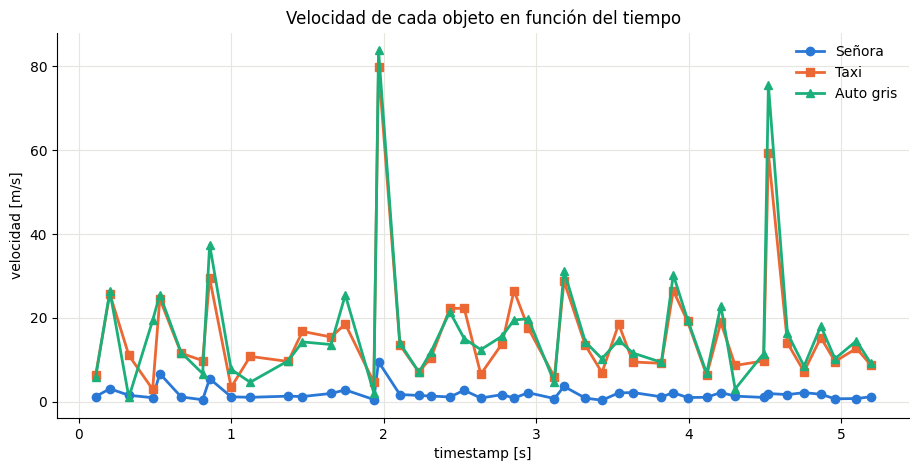

In [61]:
# Grafico la velocidad
series = [
    ("velocidad_senora", "Señora", "#2a78d6", "o"),
    ("velocidad_taxi", "Taxi", "#eb6834", "s"),
    ("velocidad_auto_gris", "Auto gris", "#1baf7a", "^"),
]

fig, ax = plt.subplots(figsize=(11, 5))
for columna, nombre, color, marcador in series:
    ax.plot(dataset["timestamp"], dataset[columna], color=color, linewidth=2,
            marker=marcador, markersize=6, label=nombre)

ax.set_xlabel("timestamp [s]")
ax.set_ylabel("velocidad [m/s]")
ax.set_title("Velocidad de cada objeto en función del tiempo")
ax.grid(True, color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

mirando el grafico hay picos muy altos, fui a revisar las fotografias y los puntos entre fotos consecutivos estan bien hechos pero el timestamp es muy corto para el movimiento que podria haberse realizado en ese punto por lo que se puede sugerir que el timestamp de la foto esta mal o se grabó de manera incorrecta por lo que voy a proceder a quitarlos

In [62]:
# Saco las filas 15 y 38. Los puntos están bien, pero el timestamp de esas dos fotos no se corresponde
# con el movimiento, el timestamp de la foto esta mal o se grabó de manera incorrecta
dataset_filtrado = dataset.drop(index=[15, 38])

dataset_filtrado["X_seniora_diff"] = dataset_filtrado["X_seniora"].diff()
dataset_filtrado["Y_seniora_diff"] = dataset_filtrado["Y_seniora"].diff()
dataset_filtrado["X_taxi_diff"] = dataset_filtrado["X_taxi"].diff()
dataset_filtrado["Y_taxi_diff"] = dataset_filtrado["Y_taxi"].diff()
dataset_filtrado["X_auto_gris_diff"] = dataset_filtrado["X_auto_gris"].diff()
dataset_filtrado["Y_auto_gris_diff"] = dataset_filtrado["Y_auto_gris"].diff()
dataset_filtrado["dt"] = dataset_filtrado["timestamp"].diff()
dataset_filtrado["distancia_senora"] = np.sqrt((dataset_filtrado["X_seniora_diff"]**2) + (dataset_filtrado["Y_seniora_diff"]**2))
dataset_filtrado["velocidad_senora"] = dataset_filtrado["distancia_senora"] / dataset_filtrado["dt"]
dataset_filtrado["distancia_taxi"] = np.sqrt((dataset_filtrado["X_taxi_diff"]**2) + (dataset_filtrado["Y_taxi_diff"]**2))
dataset_filtrado["velocidad_taxi"] = dataset_filtrado["distancia_taxi"] / dataset_filtrado["dt"]
dataset_filtrado["distancia_auto_gris"] = np.sqrt((dataset_filtrado["X_auto_gris_diff"]**2) + (dataset_filtrado["Y_auto_gris_diff"]**2))
dataset_filtrado["velocidad_auto_gris"] = dataset_filtrado["distancia_auto_gris"] / dataset_filtrado["dt"]

dataset_filtrado[["timestamp", "dt", "velocidad_senora", "velocidad_taxi", "velocidad_auto_gris"]]

,timestamp,dt,velocidad_senora,velocidad_taxi,velocidad_auto_gris
0,0.000,NaN,NaN,NaN,NaN
1,0.110,0.110,1.198466,6.317374,5.768291
2,0.203,0.093,3.061176,25.698706,26.335856
3,0.328,0.125,1.503508,11.023905,1.000047
4,0.484,0.156,0.927866,2.929345,19.369489
5,0.531,0.047,6.671353,24.500287,25.541651
6,0.671,0.140,1.110857,11.545026,11.698150
7,0.812,0.141,0.436236,9.775062,6.683224
8,0.858,0.046,5.459675,29.419089,37.419756
9,0.999,0.141,1.139907,3.402079,7.670172


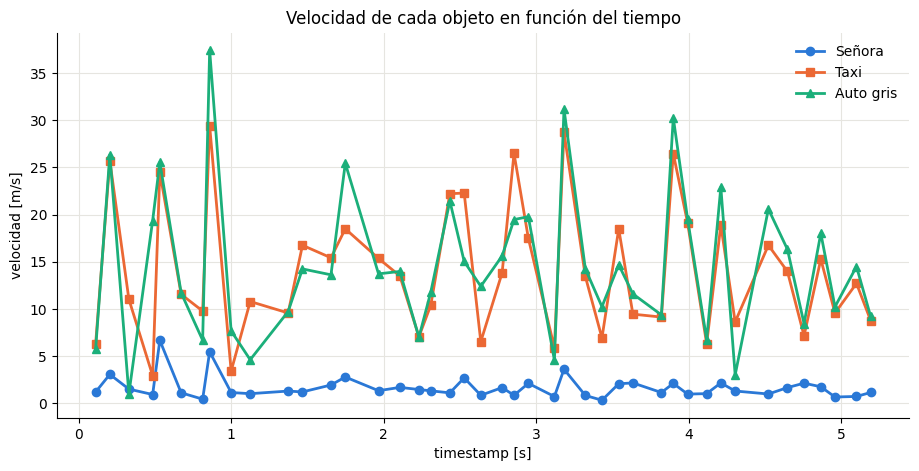

In [64]:
# Grafico la velocidad
series = [
    ("velocidad_senora", "Señora", "#2a78d6", "o"),
    ("velocidad_taxi", "Taxi", "#eb6834", "s"),
    ("velocidad_auto_gris", "Auto gris", "#1baf7a", "^"),
]

fig, ax = plt.subplots(figsize=(11, 5))
for columna, nombre, color, marcador in series:
    ax.plot(dataset_filtrado["timestamp"], dataset_filtrado[columna], color=color, linewidth=2,
            marker=marcador, markersize=6, label=nombre)

ax.set_xlabel("timestamp [s]")
ax.set_ylabel("velocidad [m/s]")
ax.set_title("Velocidad de cada objeto en función del tiempo")
ax.grid(True, color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

### Ejercicio 6 - Aterrizaje suave

a) Aplicar POSIT para encontrar la pose ($\mathbf{R}$ y $\mathbf{t}$) de la cámara del Drone a partir de la imagen $\texttt{row\_00248.png}$. La cámara tiene la matriz intrínseca $\mathbf{K}$. 

b) Estimar la matriz de rotación y traslación para ubicar al drone exactamente sobre la letra H y que la cámara la vea vertical (el punto blanco marca la parte superior izquierda)

---